## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:

nombre_estudiante = ""
carnet = None


## 1) Descripción del problema **[1 pts]**
Un grupo de personas nesecitan conectar unos componentes en una protoboard y nececitan saber como pueden conectar todos los componentes sin que se repitan y usando la menor cantidad de cable para las conecciones, nuestro trabajo es hacer un programa que simule la posicion de los componentes y analice cual es el camino mas corto para conectar cada componente. 

## 2) Requerimientos **[2 pts]**

**funcionales**
RF01: El sistema debe registrar los componentes con identificadores y posiciones

RF02: el código debe representar una protoboard con sus filas y columnas respectivas

RF03: el código debe colocar los componentes en su posición indicada

RF04: El código debe poder calcular la distancia entre dos componentes

RF05: el código debe poder implementar el algoritmo de kruskal para el árbol de expansión minima

**no funcionales**
RNF-01: el código debe realizarse en Python y ejecutarse en jupyter

RNF-02: el código debe ser organizado en funciones para su fácil mantenimiento

RNF-03: Las representaciones gráficas deben ser claras y permitir identificar los componentes, las filas, las columnas y las conexiones.

RNF-04: los cálculos de las distancias entre componentes se deben hacer de manera automática

RNF-05: los cálculos para las distancias entre componentes deben ser hecho por el algoritmo de krushkal



## 3) Historias de usuario **[2 pts]**
HU01.  Como usuario, quiero visualizar una protoboard con sus filas y columnas para ubicar gráficamente los siete componentes electrónicos en las posiciones indicadas.
Criterios de aceptación:
* Mostrar las filas de la A a la J.
* Mostrar las columnas de la 1 a la 30.
* Ubicar los siete componentes en sus posiciones correspondientes.
* Identificar cada componente mediante su letra.

HU02.  Como usuario, quiero que el programa calcule automáticamente la distancia entre cada pareja de componentes para conocer la longitud de cable necesaria para conectarlos.
Criterios de aceptación:
* Utilizar las coordenadas de cada componente.
* Aplicar la fórmula de distancia Manhattan.
* Calcular las distancias sin ingresar manualmente los pesos.

HU03. Como usuario, quiero representar los componentes mediante vértices y las conexiones mediante aristas para visualizar todas las conexiones posibles y sus respectivos pesos.
Criterios de aceptación:
* Representar los siete componentes como vértices.
* Conectar cada pareja de componentes.
* Mostrar el peso de cada conexión.

HU04. Como usuario, quiero que el programa implemente el algoritmo de Kruskal para seleccionar las conexiones de menor longitud sin formar ciclos.
Criterios de aceptación:

* Ordenar las aristas de menor a mayor peso.
* Seleccionar las conexiones más cortas.
* Evitar la formación de ciclos.
* Obtener exactamente seis conexiones.

HU05. Como usuario, quiero visualizar la protoboard con únicamente las conexiones seleccionadas por Kruskal para identificar el cableado óptimo.
Criterios de aceptación:

* Mostrar los siete componentes.
* Dibujar únicamente las seis conexiones seleccionadas.
* Mostrar la longitud de cada cable.
* Calcular y mostrar la longitud total del cable utilizado.


## 4) Diagramas de flujo **[5 pts]**
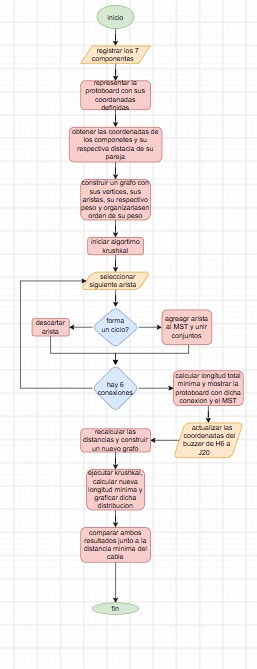

### 5) Análisis de complejidad **[15 pts]**
el análisis de complejidad de este programa es el mejor caso (grafica verde) de O(n2 ) ya que genera las aristas y actualiza los grupos en orden cuadrático y el peor caso (grafica azul) es O(n2 log n) por el algoritmo que usamos para el ordenamiento. 

Mejor caso O(n^2)
peor caso O(n log n)
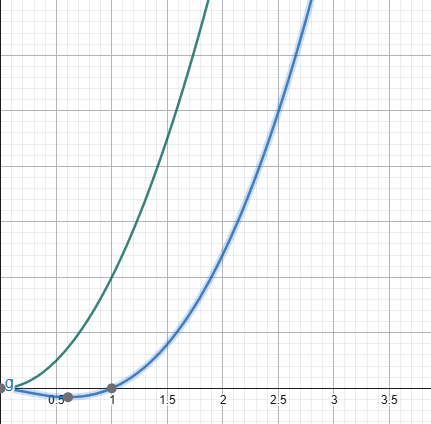


## 6) Código funcional **[15 pts]**



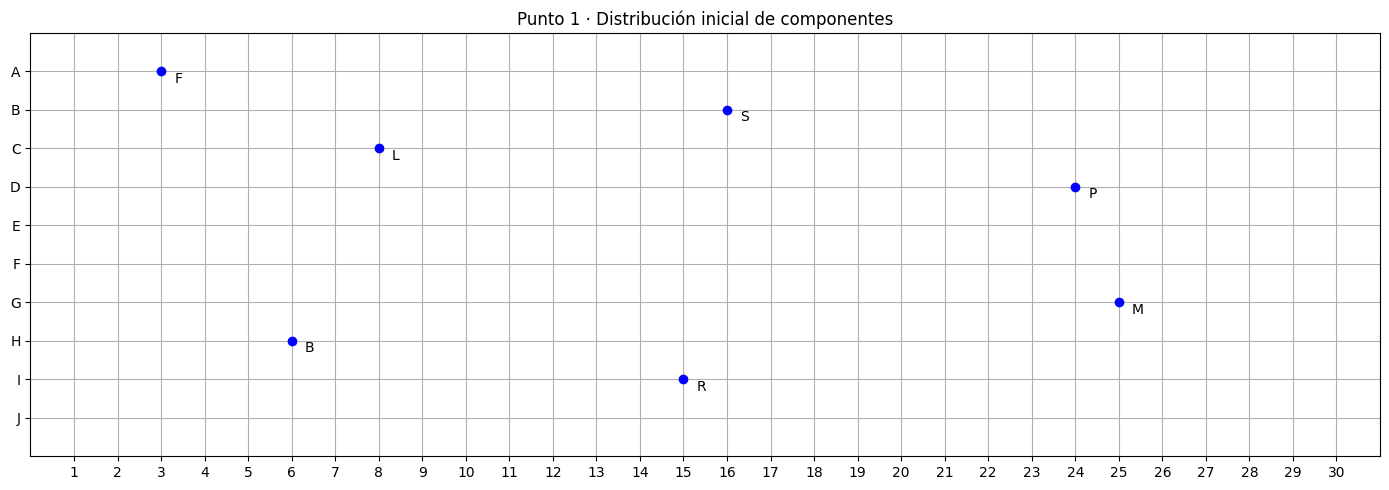

Puntos 2 y 3 · Todas las conexiones posibles
Conexión | Longitud
M - P | 4
B - L | 7
F - L | 7
R - S | 8
L - S | 9
B - F | 10
B - R | 10
P - S | 10
M - R | 12
L - R | 13
F - S | 14
M - S | 14
P - R | 14
B - S | 16
L - P | 17
B - M | 20
F - R | 20
L - M | 21
B - P | 22
F - P | 24
F - M | 28


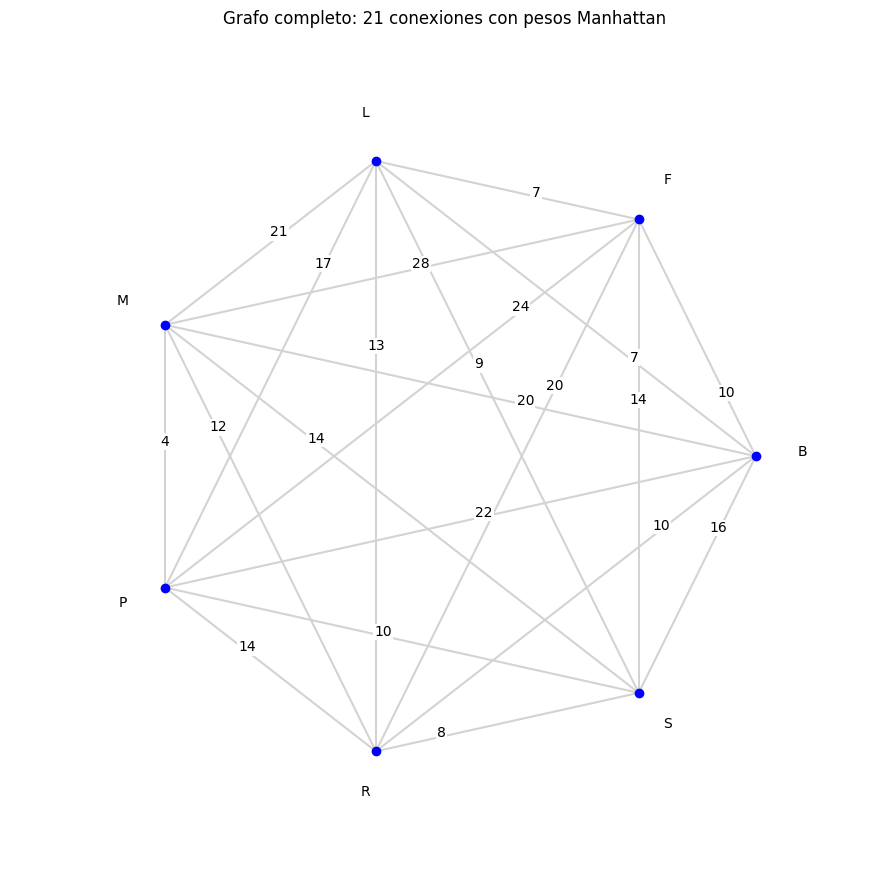


Punto 4 · Prueba de escritorio de Kruskal
Paso 1: M-P, peso 4: Aceptar. Acumulado: 4
Paso 2: B-L, peso 7: Aceptar. Acumulado: 11
Paso 3: F-L, peso 7: Aceptar. Acumulado: 18
Paso 4: R-S, peso 8: Aceptar. Acumulado: 26
Paso 5: L-S, peso 9: Aceptar. Acumulado: 35
Paso 6: B-F, peso 10: Descartar: ciclo. Acumulado: 35
Paso 7: B-R, peso 10: Descartar: ciclo. Acumulado: 35
Paso 8: P-S, peso 10: Aceptar. Acumulado: 45

Punto 5 · Resultado
Cables seleccionados
Conexión | Longitud
M - P | 4
B - L | 7
F - L | 7
R - S | 8
L - S | 9
P - S | 10
Longitud total de cable: 45 unidades


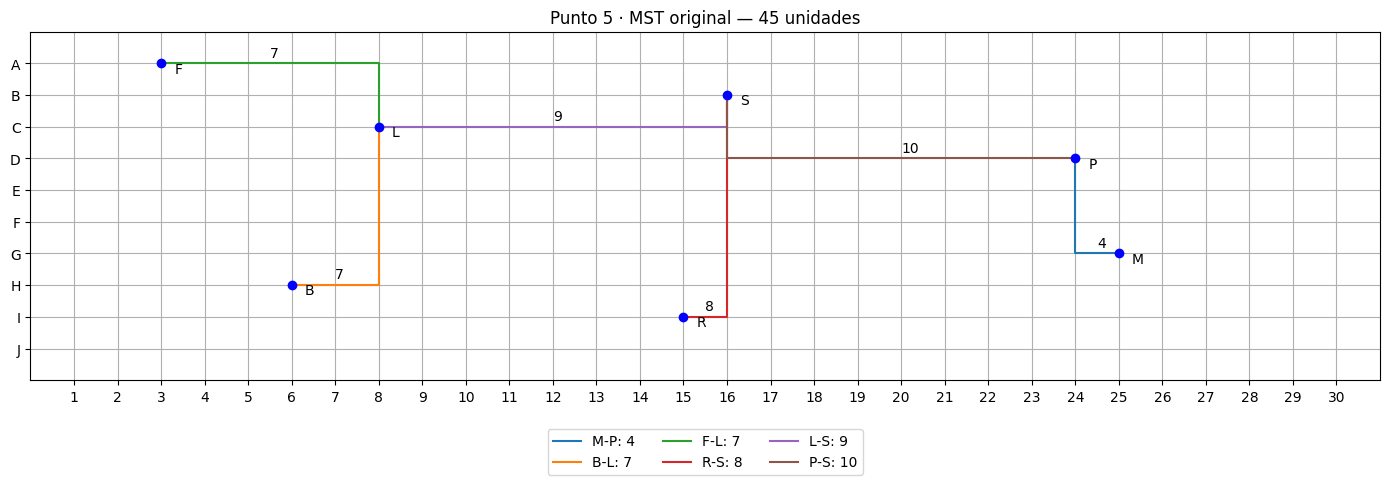


Punto 6 · Cambio del buzzer a J20
Cables seleccionados después del cambio
Conexión | Longitud
M - P | 4
B - R | 6
F - L | 7
B - M | 8
R - S | 8
L - S | 9
MST original: 45 unidades
MST después del cambio: 42 unidades


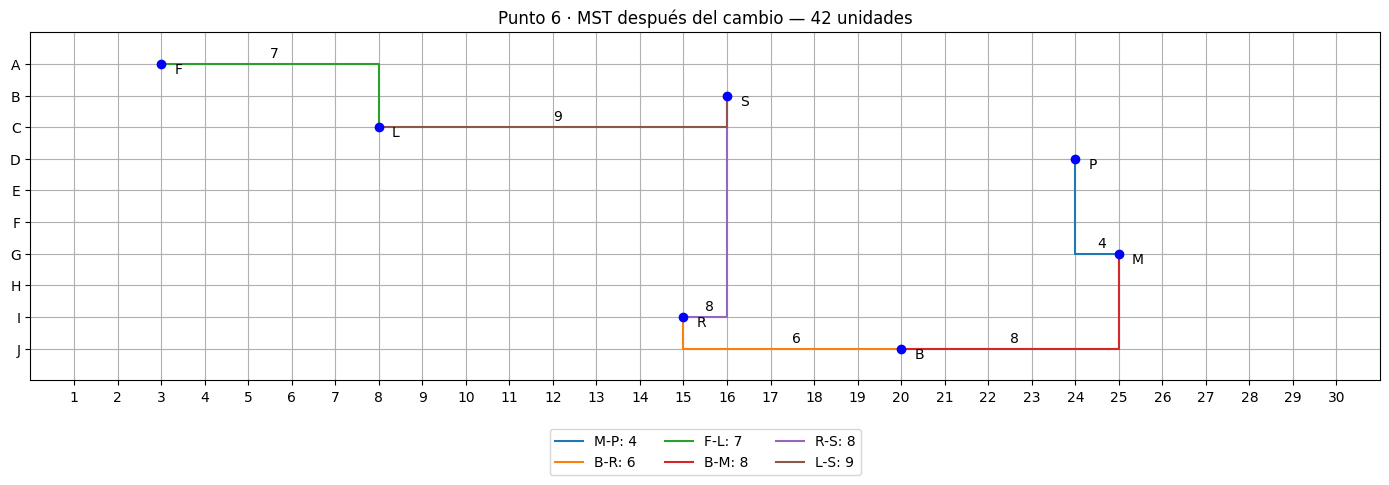

La cantidad total de cable disminuyó en 3 unidades.


In [2]:
import matplotlib.pyplot as plt
import math

NOMBRES = {
    "F": "Fuente", "L": "LED", "S": "Sensor", "P": "Pulsador",
    "B": "Buzzer", "R": "Potenciómetro", "M": "Microcontrolador"
}
POSICIONES = {
    "F": "A3", "L": "C8", "S": "B16", "P": "D24",
    "B": "H6", "R": "I15", "M": "G25"
}

def coordenada(posicion):
    
    filas = "ABCDEFGHIJ"
    if not isinstance(posicion, str) or len(posicion) < 2:
        raise ValueError("Escribe una posición como A3.")
    letra = posicion[0].upper()
    numero = posicion[1:]
    if letra not in filas or not numero.isdigit():
        raise ValueError("Usa filas A-J y columnas 1-30.")
    columna = int(numero)
    if columna < 1 or columna > 30:
        raise ValueError("La columna debe estar entre 1 y 30.")
    fila = filas.index(letra) + 1
    return columna, fila

def distancia(punto1, punto2):
    
    x1, y1 = punto1
    x2, y2 = punto2
    return abs(x1 - x2) + abs(y1 - y2)

def construir_grafo(posiciones):
    puntos = {}
    for nombre, posicion in posiciones.items():
        puntos[nombre] = coordenada(posicion)

    nombres = sorted(puntos)
    aristas = []
    for i in range(len(nombres)):
        
        for j in range(i + 1, len(nombres)):
            origen = nombres[i]
            destino = nombres[j]
            peso = distancia(puntos[origen], puntos[destino])
            aristas.append((peso, origen, destino))
    return puntos, aristas

def mostrar_tabla(aristas, titulo):
    print(titulo)
    print("Conexión | Longitud")
    for peso, origen, destino in aristas:
        print(origen, "-", destino, "|", peso)

def merge_sort(elementos):
    
    if len(elementos) <= 1:
        return elementos[:]

    mitad = len(elementos) // 2
    izquierda = merge_sort(elementos[:mitad])
    derecha = merge_sort(elementos[mitad:])

    resultado = []
    i = 0
    j = 0
    
    while i < len(izquierda) and j < len(derecha):
        if izquierda[i] <= derecha[j]:
            resultado.append(izquierda[i])
            i += 1
        else:
            resultado.append(derecha[j])
            j += 1

    
    resultado.extend(izquierda[i:])
    resultado.extend(derecha[j:])
    return resultado


def encontrar(padre, vertice):
    
    if padre[vertice] != vertice:
        
        padre[vertice] = encontrar(padre, padre[vertice])
    return padre[vertice]


def unir(padre, rango, origen, destino):
    raiz1 = encontrar(padre, origen)
    raiz2 = encontrar(padre, destino)
    if raiz1 == raiz2:
        return False  

    
    if rango[raiz1] < rango[raiz2]:
        padre[raiz1] = raiz2
    elif rango[raiz1] > rango[raiz2]:
        padre[raiz2] = raiz1
    else:
        padre[raiz2] = raiz1
        rango[raiz1] += 1
    return True


def kruskal(vertices, aristas):
    vertices = list(vertices)
    if len(vertices) <= 1:
        return [], 0, []

    padre = {}
    rango = {}
    for vertice in vertices:
        padre[vertice] = vertice
        rango[vertice] = 0

    mst = []       
    total = 0      
    traza = []     
    ordenadas = merge_sort(aristas)

    for peso, origen, destino in ordenadas:
        if unir(padre, rango, origen, destino):
            mst.append((peso, origen, destino))
            total += peso
            decision = "Aceptar"
        else:
            decision = "Descartar: ciclo"

        traza.append((origen, destino, peso, decision, total))
        if len(mst) == len(vertices) - 1:
            break

    if len(mst) != len(vertices) - 1:
        raise ValueError("El grafo está desconectado.")
    return mst, total, traza


def mostrar_traza(traza):
    for paso, datos in enumerate(traza, start=1):
        origen, destino, peso, decision, total = datos
        print(f"Paso {paso}: {origen}-{destino}, peso {peso}: "
            f"{decision}. Acumulado: {total}")

def dibujar_protoboard(posiciones, aristas=None, titulo="Protoboard"):
    plt.figure(figsize=(14, 5))
    puntos = {}
    for nombre, posicion in posiciones.items():
        puntos[nombre] = coordenada(posicion)

    
    if aristas:
        for peso, origen, destino in aristas:
            x1, y1 = puntos[origen]
            x2, y2 = puntos[destino]
            plt.plot([x1, x2, x2], [y1, y1, y2],
                    label=f"{origen}-{destino}: {peso}")
            plt.text((x1 + x2) / 2, y1 - 0.2, str(peso))
        plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)

    
    for nombre, (x, y) in puntos.items():
        plt.plot(x, y, "bo")
        plt.text(x + 0.3, y + 0.3, nombre)

    plt.xticks(range(1, 31))
    plt.yticks(range(1, 11), list("ABCDEFGHIJ"))
    plt.xlim(0, 31)
    plt.ylim(11, 0)
    plt.grid()
    plt.title(titulo)
    plt.tight_layout()
    plt.show()


def dibujar_grafo_completo(puntos, aristas):
    
    nombres = sorted(puntos)
    circulo = {}
    for i, nombre in enumerate(nombres):
        angulo = 2 * math.pi * i / len(nombres)
        circulo[nombre] = (math.cos(angulo), math.sin(angulo))

    plt.figure(figsize=(9, 9))
    for i, (peso, origen, destino) in enumerate(aristas):
        x1, y1 = circulo[origen]
        x2, y2 = circulo[destino]
        plt.plot([x1, x2], [y1, y2], color="lightgray")
        
        lugar = 0.25 + 0.07 * (i % 4)
        x = x1 + lugar * (x2 - x1)
        y = y1 + lugar * (y2 - y1)
        plt.text(x, y, str(peso), ha="center",
                bbox=dict(facecolor="white", edgecolor="none", pad=1))

    for nombre, (x, y) in circulo.items():
        plt.plot(x, y, "bo")
        plt.text(x * 1.15, y * 1.15, nombre, ha="center")
    plt.title("Grafo completo: 21 conexiones con pesos Manhattan")
    plt.xlim(-1.4, 1.4)
    plt.ylim(-1.4, 1.4)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

puntos_originales, aristas_originales = construir_grafo(POSICIONES)
dibujar_protoboard(POSICIONES, titulo='Punto 1 · Distribución inicial de componentes')
mostrar_tabla(merge_sort(aristas_originales), 'Puntos 2 y 3 · Todas las conexiones posibles')
dibujar_grafo_completo(puntos_originales, aristas_originales)
mst_original, total_original, traza_original = kruskal(puntos_originales, aristas_originales)
print('\nPunto 4 · Prueba de escritorio de Kruskal')
mostrar_traza(traza_original)
print('\nPunto 5 · Resultado')
mostrar_tabla(mst_original, 'Cables seleccionados')
print(f'Longitud total de cable: {total_original} unidades')
dibujar_protoboard(POSICIONES, mst_original,
                f'Punto 5 · MST original — {total_original} unidades')

# Punto 6: mover el buzzer y recalcular las conexiones.
posiciones_nuevas = POSICIONES.copy()
posiciones_nuevas['B'] = 'J20'
puntos_nuevos, aristas_nuevas = construir_grafo(posiciones_nuevas)
mst_nuevo, total_nuevo, traza_nueva = kruskal(puntos_nuevos, aristas_nuevas)

print('\nPunto 6 · Cambio del buzzer a J20')
mostrar_tabla(mst_nuevo, 'Cables seleccionados después del cambio')
print(f'MST original: {total_original} unidades')
print(f'MST después del cambio: {total_nuevo} unidades')
dibujar_protoboard(posiciones_nuevas, mst_nuevo,
                  f'Punto 6 · MST después del cambio — {total_nuevo} unidades')

diferencia = total_nuevo - total_original
if diferencia < 0:
    print(f'La cantidad total de cable disminuyó en {-diferencia} unidades.')
elif diferencia > 0:
    print(f'La cantidad total de cable aumentó en {diferencia} unidades.')
else:
    print('La cantidad total de cable no cambió.')


## 7) Tests aplicados **[15 pts]**

In [3]:
from itertools import combinations

# assert detiene el programa si una condición no se cumple.
def es_arbol(vertices, aristas):
    vertices = list(vertices)
    if not vertices:
        return len(aristas) == 0
    if len(aristas) != len(vertices)-1:
        return False
    adyacencia = {v: [] for v in vertices}
    parejas = set()
    for _,u,v in aristas:
        pareja = frozenset((u,v))
        if u == v or u not in adyacencia or v not in adyacencia or pareja in parejas:
            return False
        parejas.add(pareja)
        adyacencia[u].append(v)
        adyacencia[v].append(u)
    visitados = set()
    pila = [vertices[0]]
    while pila:
        u = pila.pop()
        if u not in visitados:
            visitados.add(u)
            for vecino in adyacencia[u]:
                if vecino not in visitados:
                    pila.append(vecino)
    return len(visitados) == len(vertices)

def minimo_exhaustivo(vertices, aristas):
    mejor = math.inf
    revisadas = 0
    for seleccion in combinations(aristas, len(vertices)-1):
        revisadas += 1
        if es_arbol(vertices, seleccion):
            mejor = min(mejor, sum(peso for peso,_,_ in seleccion))
    return mejor, revisadas

def probar_error(funcion, *args):
    try:
        funcion(*args)
    except ValueError:
        return True
    return False

assert coordenada('A3') == (3,1)
assert coordenada('J30') == (30,10)
assert distancia((3,1),(8,3)) == 7
assert distancia((8,3),(3,1)) == 7
assert distancia((3,1),(3,1)) == 0
assert all(probar_error(coordenada,p) for p in ['K3','A0','J31','A','3A'])
assert len(aristas_originales) == 21
assert len({frozenset((u,v)) for _,u,v in aristas_originales}) == 21
assert all(u != v for _,u,v in aristas_originales)
assert merge_sort(aristas_originales) == sorted(aristas_originales)
assert all(peso == distancia(puntos_originales[u],puntos_originales[v])
           for peso,u,v in aristas_originales)
print('OK · Coordenadas, distancias, validación, grafo y ordenamiento.')

for puntos, aristas, mst, total, esperado in [
    (puntos_originales,aristas_originales,mst_original,total_original,45),
    (puntos_nuevos,aristas_nuevas,mst_nuevo,total_nuevo,42)]:
    assert es_arbol(puntos,mst)
    assert len(mst) == 6
    assert all(arista in aristas for arista in mst)
    assert total == sum(peso for peso,_,_ in mst) == esperado
    minimo, revisadas = minimo_exhaustivo(puntos, aristas)
    assert minimo == total
    assert revisadas == 54264
    print(f'OK · MST de {total} unidades: conectado, sin ciclos y mínimo entre {revisadas:,} combinaciones.')

assert POSICIONES['B'] == 'H6' and posiciones_nuevas['B'] == 'J20'
assert puntos_nuevos['B'] == (20,10)
assert total_nuevo - total_original == -3
antes = {(u,v):p for p,u,v in aristas_originales}
despues = {(u,v):p for p,u,v in aristas_nuevas}
assert all(antes[par] == despues[par] for par in antes if 'B' not in par)
assert antes[('B','R')] == 10 and despues[('B','R')] == 6
assert kruskal([],[]) == ([],0,[])
assert kruskal(['F'],[]) == ([],0,[])
assert kruskal(['F','L'],[(7,'F','L')])[1] == 7
assert probar_error(kruskal, ['F','L','S'], [(7,'F','L')])
# Un triángulo obliga a descartar una arista antes de conectar el cuarto vértice.
prueba = [(1,'A','B'),(2,'B','C'),(3,'A','C'),(10,'C','D')]
arbol, total, traza = kruskal(['A','B','C','D'],prueba)
assert total == 13 and es_arbol(['A','B','C','D'],arbol)
assert any(fila[3] == 'Descartar: ciclo' for fila in traza)
print('OK · Actualización automática, copia original, casos límite y rechazo de ciclos.')
print('TODAS LAS PRUEBAS SUPERADAS.')


OK · Coordenadas, distancias, validación, grafo y ordenamiento.
OK · MST de 45 unidades: conectado, sin ciclos y mínimo entre 54,264 combinaciones.
OK · MST de 42 unidades: conectado, sin ciclos y mínimo entre 54,264 combinaciones.
OK · Actualización automática, copia original, casos límite y rechazo de ciclos.
TODAS LAS PRUEBAS SUPERADAS.
